# Baseline Comparison

## 0. 분석 개요

ResNet18 기반 Scratch, Feature Extraction, Full Fine-tuning의
기준선 실험 결과를 비교한다.

기존에 저장된 실험 결과를 활용하며 모델을 다시 학습하지 않는다.

### 분석 목적

- 학습 전략별 분류 성능 및 학습 효율 비교
- 학습 과정 및 과적합 양상 비교
- 클래스별 성능 및 혼동 패턴 비교
- 이미지 단위 예측 변화 분석
- 후속 튜닝 및 개선 실험 방향 설정

### 분석 기준

- 평가 데이터: Validation 160장
- 핵심 평가 지표: Macro F1-score
- Checkpoint 선정 기준: 최대 Validation Macro F1
- 비교 대상: Scratch, Feature Extraction, Full Fine-tuning

Test 데이터는 최종 모델 및 설정 확정 이후 평가한다.

## 1. 실험 조건 및 데이터 준비

세 기준선 실험의 저장된 결과를 불러오고,
비교에 필요한 실험 조건과 데이터 일관성을 확인한다.

### 1.1 환경 설정 및 결과 로드

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score

# 프로젝트 경로
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src").exists() and (p / "results").exists()
)

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 비교 대상
EXPERIMENTS = {
    "Scratch": "scratch_baseline",
    "Feature Extraction": "feature_extraction_baseline",
    "Full Fine-tuning": "fine_tuning_baseline"
}

MODEL_ORDER = list(EXPERIMENTS)

MODEL_COLORS = {
    "Scratch": "#94A3B8",
    "Feature Extraction": "#0D9488",
    "Full Fine-tuning": "#6366F1"
}

sns.set_theme(style="whitegrid")

RESULT_TYPES = [
    "history",
    "summary",
    "evaluation",
    "class_report",
    "confusion_matrix",
    "confusion_pairs",
    "predictions"
]

results = {
    model_name: {
        result_type: pd.read_csv(
            RESULTS_DIR / f"{experiment}_{result_type}.csv"
        )
        for result_type in RESULT_TYPES
    }
    for model_name, experiment in EXPERIMENTS.items()
}

print(f"Loaded: {len(EXPERIMENTS)} experiments")
print(f"Total: {len(EXPERIMENTS) * len(RESULT_TYPES)} CSV files")

Loaded: 3 experiments
Total: 21 CSV files


### 1.2 실험 조건 비교

공통 실험 조건을 유지한 상태에서 사전학습 가중치,
학습 범위 및 학습률을 달리하여 세 학습 전략을 비교한다.

**공통 조건**

- Model: ResNet18
- Input Size: 224 × 224
- Train / Validation: 640 / 160
- Batch Size: 32
- Epochs: 30
- Random Seed: 42
- Optimizer: Adam
- Loss: CrossEntropyLoss
- Weight Decay: 0
- Data Augmentation: None
- Scheduler: None
- Checkpoint: Best Validation Macro F1

| 학습 조건 | Scratch | Feature Extraction | Full Fine-tuning |
|---|---|---|---|
| 초기 가중치 | Random | ImageNet | ImageNet |
| Backbone | 학습 | 동결 | 학습 |
| FC Layer | 학습 | 학습 | 학습 |
| Backbone LR | 1e-3 | - | 1e-4 |
| FC LR | 1e-3 | 1e-3 | 1e-3 |
| BatchNorm 통계 | 업데이트 | 고정 | 업데이트 |

학습 전략별로 학습률과 학습 범위가 다르므로,
성능 차이를 사전학습 가중치만의 영향으로 해석하지 않는다.

### 1.3 데이터 일관성 검증

세 모델이 동일한 Validation 이미지와 정답 라벨을 사용했는지 확인하고,
저장된 평가 지표와 예측 결과의 일치 여부를 검증한다.

In [2]:
reference = (
    results["Scratch"]["predictions"]
    .sort_values("image_id")
    .reset_index(drop=True)
)

for model_name in MODEL_ORDER:

    pred = (
        results[model_name]["predictions"]
        .sort_values("image_id")
        .reset_index(drop=True)
    )

    evaluation = results[model_name]["evaluation"].iloc[0]

    # 평가 데이터 일치 여부
    assert len(pred) == 160, model_name
    assert pred["image_id"].is_unique, model_name
    assert pred["split"].eq("val").all(), model_name
    assert pred["image_id"].equals(reference["image_id"]), model_name
    assert pred["y_true"].equals(reference["y_true"]), model_name

    # 핵심 평가 지표 일치 여부
    assert np.isclose(
        accuracy_score(pred["y_true"], pred["y_pred"]),
        evaluation["accuracy"],
        atol=1e-6
    ), model_name

    assert np.isclose(
        f1_score(pred["y_true"], pred["y_pred"], average="macro"),
        evaluation["macro_f1"],
        atol=1e-6
    ), model_name

print("All validation checks passed.")

All validation checks passed.


## 2. 전체 성능 및 학습 효율 비교

Validation 평가 지표, 학습 가능 파라미터 수 및 학습 시간을
비교하여 학습 전략별 성능과 비용의 Trade-off를 분석한다.

### 2.1 전체 성능 및 학습 효율 비교표

In [3]:
records = []

for model_name in MODEL_ORDER:

    evaluation = results[model_name]["evaluation"].iloc[0]
    summary = results[model_name]["summary"].iloc[0]

    records.append({
        "model": model_name,
        "best_epoch": int(summary["best_epoch"]),
        "val_loss": evaluation["loss"],
        "accuracy": evaluation["accuracy"],
        "macro_precision": evaluation["macro_precision"],
        "macro_recall": evaluation["macro_recall"],
        "macro_f1": evaluation["macro_f1"],
        "trainable_params": int(summary["trainable_params"]),
        "trainable_ratio_pct": (
            summary["trainable_params"] / summary["total_params"] * 100
        ),
        "mean_epoch_time_sec": summary["mean_epoch_time_sec"],
        "total_training_time_sec": summary["total_training_time_sec"]
    })

comparison_df = pd.DataFrame(records).set_index("model")

display(
    comparison_df.style
    .format({
        "val_loss": "{:.4f}",
        "accuracy": "{:.4f}",
        "macro_precision": "{:.4f}",
        "macro_recall": "{:.4f}",
        "macro_f1": "{:.4f}",
        "trainable_params": "{:,}",
        "trainable_ratio_pct": "{:.4f}%",
        "mean_epoch_time_sec": "{:.2f}",
        "total_training_time_sec": "{:.2f}"
    })
    .highlight_max(
        subset=["accuracy", "macro_precision", "macro_recall", "macro_f1"],
        props="background-color: #d1fae5; color: #111827;"
    )
    .highlight_min(
        subset=["val_loss", "mean_epoch_time_sec", "total_training_time_sec"],
        props="background-color: #d1fae5; color: #111827;"
    )
)

,best_epoch,val_loss,accuracy,macro_precision,macro_recall,macro_f1,trainable_params,trainable_ratio_pct,mean_epoch_time_sec,total_training_time_sec
model,,,,,,,,,,
Scratch,29,1.9176,0.5875,0.5879,0.5875,0.5837,"11,180,616",100.0000%,3.31,99.90
Feature Extraction,17,0.4087,0.8812,0.8889,0.8812,0.8765,"4,104",0.0367%,2.42,73.02
Full Fine-tuning,26,0.4671,0.8938,0.8938,0.8938,0.8913,"11,180,616",100.0000%,3.25,97.81


### 2.2 성능 및 학습 시간 변화량

학습 전략 변경에 따른 Macro F1, 정분류 이미지 수,
전체 학습 시간의 변화량을 비교한다.

In [4]:
comparison_pairs = [
    ("Scratch", "Feature Extraction"),
    ("Feature Extraction", "Full Fine-tuning"),
    ("Scratch", "Full Fine-tuning")
]

change_records = []

for before, after in comparison_pairs:

    a = comparison_df.loc[before]
    b = comparison_df.loc[after]

    change_records.append({
        "comparison": f"{before} → {after}",
        "accuracy_change_pp": (b["accuracy"] - a["accuracy"]) * 100,
        "f1_change_pp": (b["macro_f1"] - a["macro_f1"]) * 100,
        "net_correct_increase": round(
            (b["accuracy"] - a["accuracy"]) * len(reference)
        ),
        "time_change_sec": (
            b["total_training_time_sec"] - a["total_training_time_sec"]
        ),
        "time_change_pct": (
            b["total_training_time_sec"] / a["total_training_time_sec"] - 1
        ) * 100
    })

change_df = pd.DataFrame(change_records).set_index("comparison")

display(change_df.round(4))

,accuracy_change_pp,f1_change_pp,net_correct_increase,time_change_sec,time_change_pct
comparison,,,,,
Scratch → Feature Extraction,29.375,29.2746,47,-26.8778,-26.9051
Feature Extraction → Full Fine-tuning,1.250,1.4866,2,24.7912,33.9509
Scratch → Full Fine-tuning,30.625,30.7612,49,-2.0866,-2.0887


### 2.3 성능 및 학습 효율 시각화

핵심 평가 지표인 Macro F1과 전체 학습 시간을 비교한다.

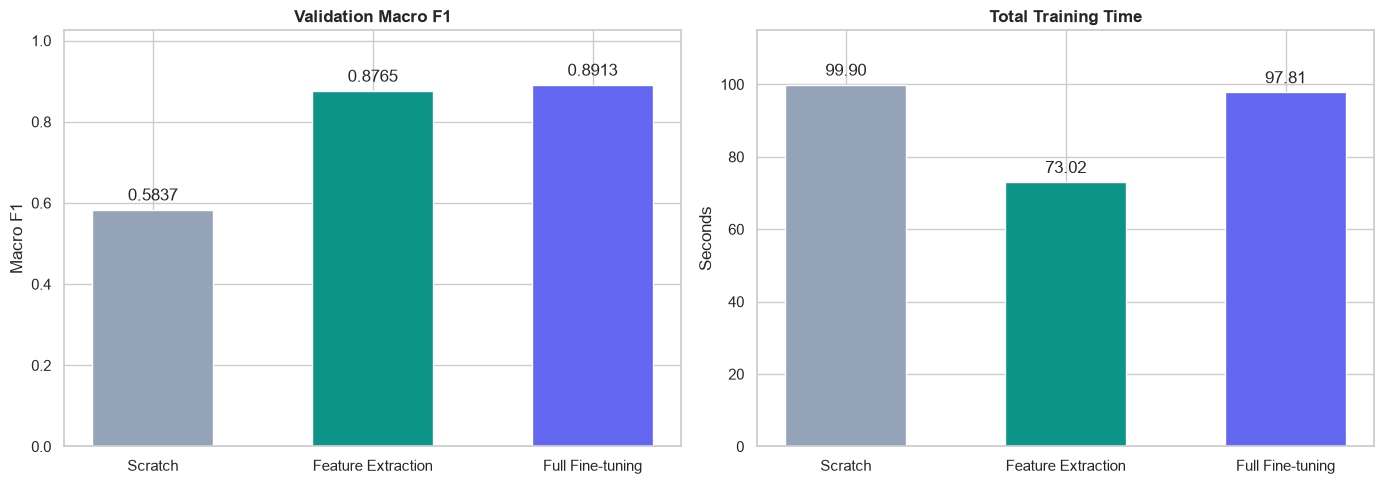

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_configs = [
    ("macro_f1", "Validation Macro F1", "Macro F1", "%.4f"),
    ("total_training_time_sec", "Total Training Time", "Seconds", "%.2f")
]

for ax, (column, title, ylabel, fmt) in zip(axes, plot_configs):

    bars = ax.bar(
        MODEL_ORDER,
        comparison_df[column],
        color=[MODEL_COLORS[m] for m in MODEL_ORDER],
        width=0.55
    )

    ax.bar_label(bars, fmt=fmt, padding=4)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, comparison_df[column].max() * 1.15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_performance_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.4 결과 해석

- Feature Extraction은 Scratch 대비 Macro F1이 29.27%p 향상되었으며,
  전체 학습 시간은 26.91% 감소하였다.
  제한된 학습 데이터에서 사전학습 모델을 활용하는 전략의 효과를 확인하였다.

- Full Fine-tuning은 Macro F1 0.8913으로 가장 높은 분류 성능을 기록하였다.
  다만 Feature Extraction 대비 성능 향상은 1.49%p,
  정분류 이미지 수의 순증가는 2장에 그쳤으며 학습 시간은 33.95% 증가하였다.

- Feature Extraction은 전체 파라미터의 0.0367%만 학습하면서
  가장 짧은 학습 시간과 가장 낮은 Validation Loss를 기록하였다.

- 현재 기준선에서는 Full Fine-tuning이 분류 성능 측면에서,
  Feature Extraction이 학습 효율 측면에서 우수한 결과를 보였다.

- 단일 Seed 및 실행 환경에서 측정된 결과이므로 작은 성능 차이와
  학습 시간 차이를 과도하게 해석하지 않는다.

## 3. 학습 과정 비교

학습 전략별 Train 및 Validation Loss와 Macro F1의
변화를 비교하여 수렴 속도와 과적합 양상을 분석한다.

### 3.1 학습 곡선 비교

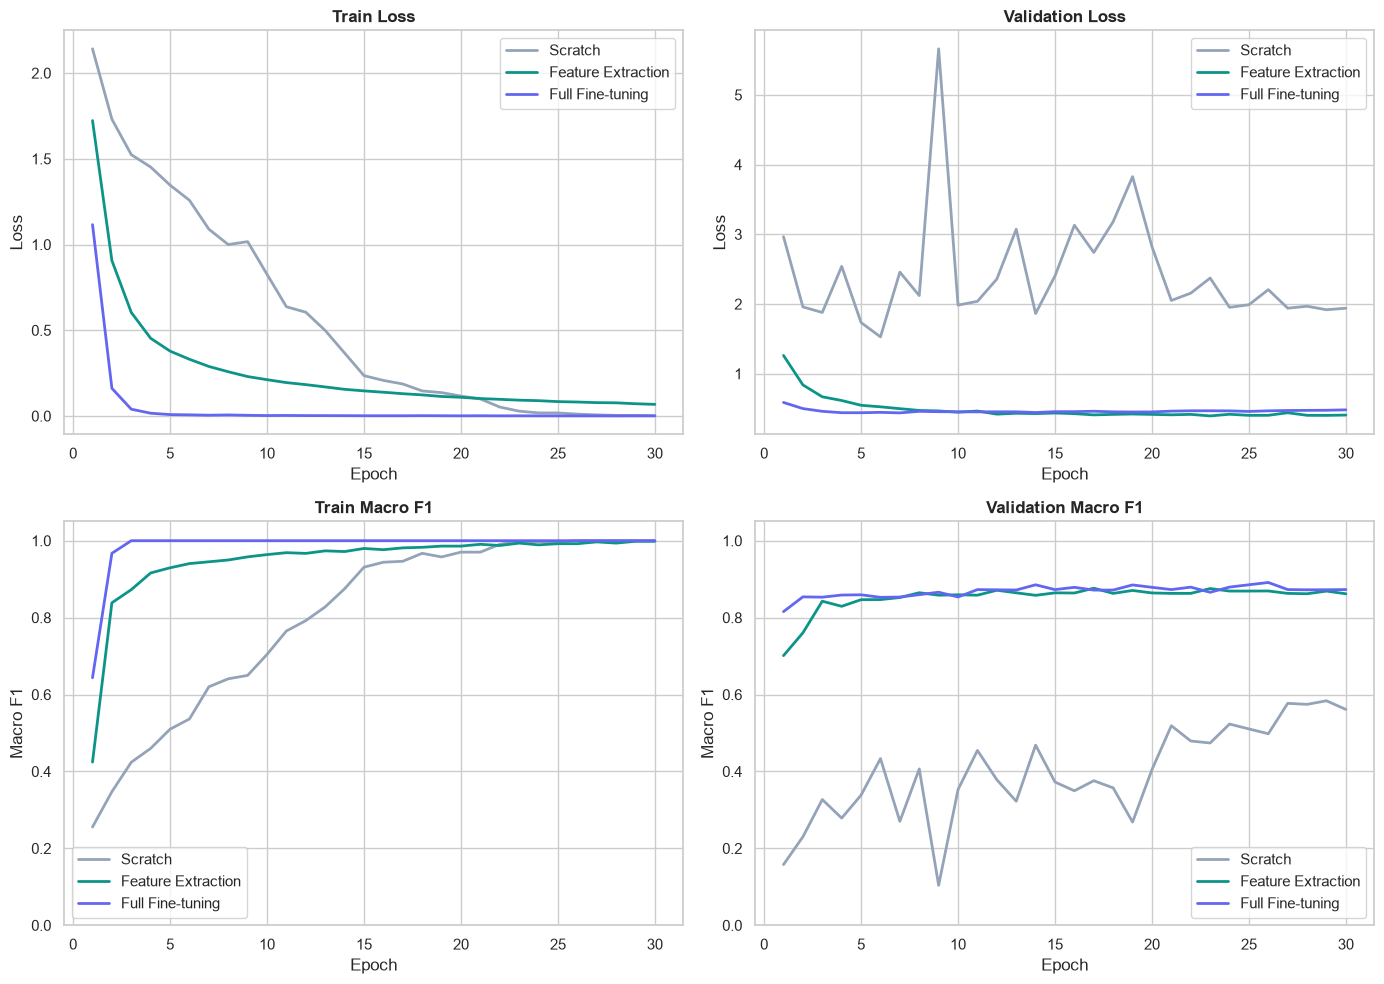

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_configs = [
    ("train_loss", "Train Loss"),
    ("val_loss", "Validation Loss"),
    ("train_f1", "Train Macro F1"),
    ("val_f1", "Validation Macro F1")
]

for ax, (column, title) in zip(axes.flat, plot_configs):

    for model_name in MODEL_ORDER:

        history = results[model_name]["history"]

        ax.plot(
            history["epoch"],
            history[column],
            label=model_name,
            color=MODEL_COLORS[model_name],
            linewidth=2
        )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Macro F1" if "f1" in column else "Loss")
    ax.legend()

    if "f1" in column:
        ax.set_ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.2 Train–Validation 성능 격차 비교

최적 Checkpoint에서의 Train 및 Validation 성능 격차를
비교하여 학습 전략별 과적합 양상을 확인한다.

In [7]:
gap_records = []

for model_name in MODEL_ORDER:

    summary = results[model_name]["summary"].iloc[0]

    gap_records.append({
        "model": model_name,
        "best_epoch": int(summary["best_epoch"]),
        "train_loss": summary["best_train_loss"],
        "val_loss": summary["best_val_loss"],
        "loss_gap": (
            summary["best_val_loss"] - summary["best_train_loss"]
        ),
        "train_f1": summary["best_train_f1"],
        "val_f1": summary["best_val_f1"],
        "f1_gap_pp": (
            summary["best_train_f1"] - summary["best_val_f1"]
        ) * 100
    })

gap_df = pd.DataFrame(gap_records).set_index("model")

display(
    gap_df.style
    .format({
        "train_loss": "{:.4f}",
        "val_loss": "{:.4f}",
        "loss_gap": "{:.4f}",
        "train_f1": "{:.4f}",
        "val_f1": "{:.4f}",
        "f1_gap_pp": "{:.2f}"
    })
)

,best_epoch,train_loss,val_loss,loss_gap,train_f1,val_f1,f1_gap_pp
model,,,,,,,
Scratch,29,0.0034,1.9176,1.9142,1.0000,0.5837,41.63
Feature Extraction,17,0.1300,0.4087,0.2787,0.9814,0.8765,10.49
Full Fine-tuning,26,0.0007,0.4671,0.4664,1.0000,0.8913,10.87


### 3.3 결과 해석

- Scratch는 학습이 진행되면서 Train Macro F1이 1.0에 도달하였으나,
  Validation Loss와 Macro F1의 변동이 크게 나타났다.
  최적 Epoch에서의 F1 격차도 41.63%p로 가장 커,
  세 학습 전략 중 과적합 양상이 가장 뚜렷하게 나타났다.

- Feature Extraction은 학습 초반에 Validation 성능이 빠르게 향상되었으며,
  이후 비교적 안정적인 학습 곡선을 보였다.
  최적 Epoch에서의 Loss 격차와 F1 격차도 가장 작았다.

- Full Fine-tuning은 3 Epoch부터 Train Macro F1이 1.0에 도달하며
  가장 빠르게 학습 데이터에 적합하였다.
  그러나 학습 후반부에는 Validation Loss가 소폭 증가하는 양상을 보여,
  추가 학습에 따른 과적합 가능성을 확인하였다.

- 사전학습 모델을 활용한 두 전략은 Scratch보다 빠른 수렴과
  높은 Validation 성능을 보였다.
  다만 Full Fine-tuning의 빠른 학습 데이터 적합이
  그만큼의 Validation 성능 향상으로 이어지지는 않았다.

- 후속 튜닝에서는 Scratch의 일반화 성능 개선과
  Full Fine-tuning의 과적합 완화를 주요 검토 대상으로 고려한다.

## 4. 클래스별 성능 및 혼동 패턴 비교

학습 전략별 클래스 성능과 혼동 패턴을 비교하여
전체 성능 차이가 발생하는 행동 유형을 파악한다.

### 4.1 클래스별 성능 비교

클래스별 Precision, Recall, F1-score를 비교하고,
F1-score를 중심으로 학습 전략별 성능 차이를 확인한다.

In [8]:
class_comparison_df = pd.concat(
    {
        model_name: results[model_name]["class_report"]
        .set_index("class_name")[["precision", "recall", "f1-score"]]
        for model_name in MODEL_ORDER
    },
    axis=1
)

display(class_comparison_df.style.format("{:.4f}"))

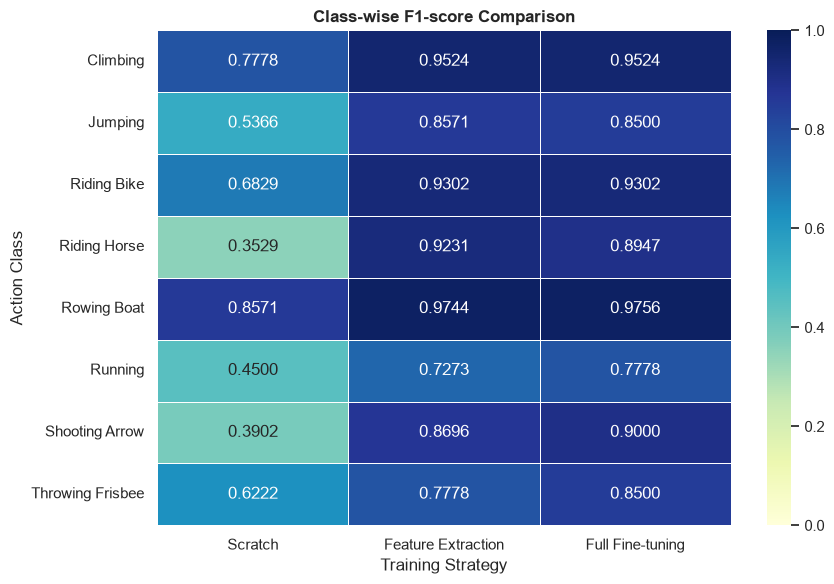

In [9]:
class_f1_df = class_comparison_df.xs(
    "f1-score",
    axis=1,
    level=1
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    class_f1_df,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Class-wise F1-score Comparison", fontweight="bold")
plt.xlabel("Training Strategy")
plt.ylabel("Action Class")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_class_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.2 Confusion Matrix 비교

세 모델의 Confusion Matrix를 비교하여
주요 혼동 클래스와 학습 전략별 오류 패턴의 변화를 확인한다.

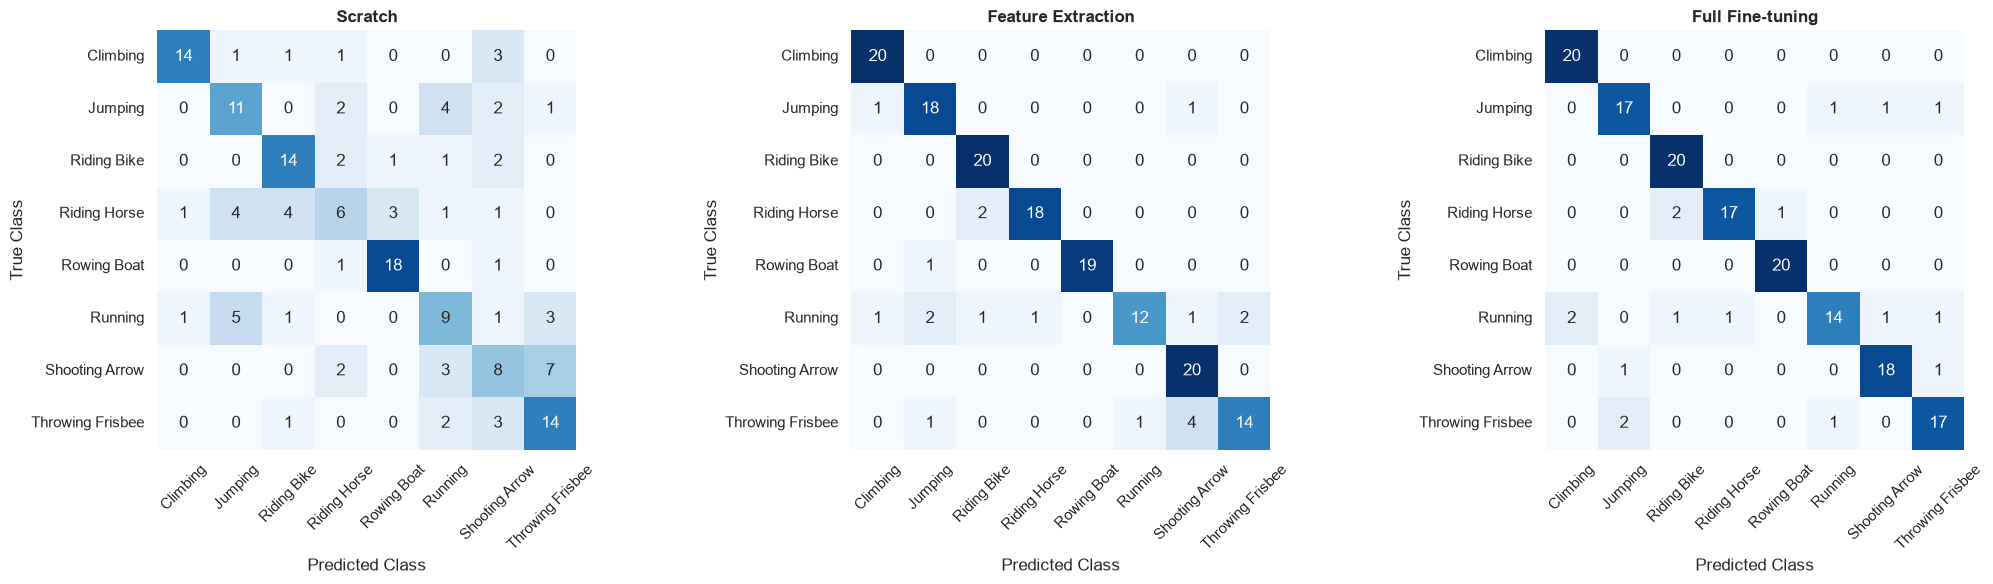

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, model_name in zip(axes, MODEL_ORDER):

    cm = (
        results[model_name]["confusion_matrix"]
        .set_index("true_class")
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=20,
        square=True,
        cbar=False,
        ax=ax
    )

    ax.set_title(model_name, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.3 주요 혼동 패턴 비교

정답 클래스와 예측 클래스의 조합별 오분류 수를 비교하여
학습 전략에 따른 주요 혼동 패턴의 변화를 확인한다.

In [11]:
confusion_comparison_df = pd.concat(
    {
        model_name: results[model_name]["confusion_pairs"]
        .set_index(["true_class", "predicted_class"])["count"]
        for model_name in MODEL_ORDER
    },
    axis=1
).fillna(0).astype(int)

confusion_comparison_df["FE_to_FT_change"] = (
    confusion_comparison_df["Full Fine-tuning"]
    - confusion_comparison_df["Feature Extraction"]
)

display(
    confusion_comparison_df
    .sort_values(
        ["Full Fine-tuning", "Feature Extraction", "Scratch"],
        ascending=False
    )
    .head(15)
)

Scratch  Feature Extraction  \
true_class       predicted_class                                 
Riding Horse     Riding Bike             4                   2   
Running          Climbing                1                   1   
Throwing Frisbee Jumping                 0                   1   
Running          Throwing Frisbee        3                   2   
Jumping          Shooting Arrow          2                   1   
Throwing Frisbee Running                 2                   1   
Running          Riding Bike             1                   1   
                 Shooting Arrow          1                   1   
                 Riding Horse            0                   1   
Shooting Arrow   Throwing Frisbee        7                   0   
Jumping          Running                 4                   0   
Riding Horse     Rowing Boat             3                   0   
Jumping          Throwing Frisbee        1                   0   
Shooting Arrow   Jumping                 0                   0   
Throwing Frisbee Shooting Arrow          3                   4   

                                   Full Fine-tuning  FE_to_FT_change  
true_class       predicted_class                                      
Riding Horse     Riding Bike                      2                0  
Running          Climbing                         2                1  
Throwing Frisbee Jumping                          2                1  
Running          Throwing Frisbee                 1               -1  
Jumping          Shooting Arrow                   1                0  
Throwing Frisbee Running                          1                0  
Running          Riding Bike                      1                0  
                 Shooting Arrow                   1                0  
                 Riding Horse                     1                0  
Shooting Arrow   Throwing Frisbee                 1                1  
Jumping          Running                          1                1  
Riding Horse     Rowing Boat                      1                1  
Jumping          Throwing Frisbee                 1                1  
Shooting Arrow   Jumping                          1                1  
Throwing Frisbee Shooting Arrow                   0               -4

### 4.4 결과 해석

- Feature Extraction은 Scratch 대비 모든 클래스에서 F1-score가 향상되었다.
  특히 Riding Horse와 Shooting Arrow에서 각각 57.02%p, 47.94%p의
  큰 성능 향상이 나타났다.

- Full Fine-tuning은 Feature Extraction 대비 Throwing Frisbee,
  Running, Shooting Arrow에서 성능이 향상되었으나,
  Riding Horse와 Jumping에서는 소폭 감소하였다.
  전체 성능 향상이 모든 클래스의 개선을 의미하지는 않았다.

- Running은 사전학습 모델을 활용한 두 전략에서 모두
  가장 낮은 F1-score를 기록하였다.
  Full Fine-tuning에서도 Recall이 0.70으로 나타나
  주요 개선 대상 클래스로 판단하였다.

- Feature Extraction에서 Throwing Frisbee를 Shooting Arrow로
  오분류한 사례는 4건이었으나 Full Fine-tuning에서는 0건으로 감소하였다.
  반면 Riding Horse를 Riding Bike로 오분류한 건수는 2건으로 유지되었다.

- 학습 전략에 따라 혼동 패턴이 달라지는 것을 확인하였다.
  실제로 어떤 이미지의 예측이 개선되거나 악화되었는지 확인하고,
  공통 오분류 사례를 중심으로 추가 오류 분석을 진행한다.

## 5. 이미지 단위 예측 변화 분석

동일한 Validation 이미지에 대한 세 모델의 예측 결과를 연결하여
학습 전략별 예측 변화와 공통 오분류 사례를 확인한다.

### 5.1 이미지별 예측 결과 통합

In [12]:
MODEL_PREFIX = {
    "Scratch": "scratch",
    "Feature Extraction": "fe",
    "Full Fine-tuning": "ft"
}

prediction_comparison_df = reference[
    ["image_id", "image_path", "y_true", "class_name"]
].set_index("image_id").copy()

for model_name, prefix in MODEL_PREFIX.items():

    pred = results[model_name]["predictions"].set_index("image_id")

    pred = pred[
        ["y_pred", "predicted_class", "confidence"]
    ].add_prefix(f"{prefix}_")

    prediction_comparison_df = prediction_comparison_df.join(pred)

    prediction_comparison_df[f"{prefix}_correct"] = (
        prediction_comparison_df[f"{prefix}_y_pred"]
        == prediction_comparison_df["y_true"]
    )

display(prediction_comparison_df.head())

,image_path,y_true,class_name,scratch_y_pred,scratch_predicted_class,scratch_confidence,scratch_correct,fe_y_pred,fe_predicted_class,fe_confidence,fe_correct,ft_y_pred,ft_predicted_class,ft_confidence,ft_correct
image_id,,,,,,,,,,,,,,,
s40_0216b979b86639cf5693,images/val/s40_0216b979b86639cf5693.jpg,5,running,1,Jumping,0.972365,False,5,Running,0.590368,True,5,Running,0.909099,True
s40_029af1e3d7b9729f517c,images/val/s40_029af1e3d7b9729f517c.jpg,7,throwing_frisby,5,Running,0.827898,False,5,Running,0.637882,False,5,Running,0.988248,False
s40_02d39f1725b5d618f932,images/val/s40_02d39f1725b5d618f932.jpg,2,riding_a_bike,2,Riding Bike,0.911213,True,2,Riding Bike,0.999889,True,2,Riding Bike,0.999997,True
s40_0318ccfcfa1ee7a6bd3a,images/val/s40_0318ccfcfa1ee7a6bd3a.jpg,0,climbing,6,Shooting Arrow,0.989604,False,0,Climbing,0.995337,True,0,Climbing,0.999861,True
s40_036fd8dc9a335330714a,images/val/s40_036fd8dc9a335330714a.jpg,6,shooting_an_arrow,5,Running,0.524085,False,6,Shooting Arrow,0.964164,True,6,Shooting Arrow,0.999978,True


### 5.2 학습 전략별 예측 변화 비교

학습 전략 간 이미지별 정·오분류 상태 변화를 비교하여
성능 향상과 저하가 발생한 실제 이미지 수를 확인한다.

In [13]:
transition_records = []

for before, after in comparison_pairs:

    a = prediction_comparison_df[
        f"{MODEL_PREFIX[before]}_correct"
    ]

    b = prediction_comparison_df[
        f"{MODEL_PREFIX[after]}_correct"
    ]

    transition_records.append({
        "comparison": f"{before} → {after}",
        "both_correct": (a & b).sum(),
        "improved": (~a & b).sum(),
        "degraded": (a & ~b).sum(),
        "both_incorrect": (~a & ~b).sum(),
        "net_improvement": (~a & b).sum() - (a & ~b).sum()
    })

transition_df = (
    pd.DataFrame(transition_records)
    .set_index("comparison")
)

display(transition_df)

,both_correct,improved,degraded,both_incorrect,net_improvement
comparison,,,,,
Scratch → Feature Extraction,89,52,5,14,47
Feature Extraction → Full Fine-tuning,136,7,5,12,2
Scratch → Full Fine-tuning,92,51,2,15,49


### 5.3 공통 오분류 및 예측 변화 사례 추출

세 모델의 공통 오분류 사례와 사전학습 전략 간
예측 개선 및 악화 사례를 추출한다.

추출된 사례는 후속 이미지 분석 및 개선 가설 수립에 활용한다.

In [14]:
df = prediction_comparison_df

# 분석 대상 이미지 추출
case_groups = {
    "All Incorrect": df[
        ~df["scratch_correct"]
        & ~df["fe_correct"]
        & ~df["ft_correct"]
    ],
    "FE & FT Incorrect": df[
        ~df["fe_correct"] & ~df["ft_correct"]
    ],
    "FE → FT Improved": df[
        ~df["fe_correct"] & df["ft_correct"]
    ],
    "FE → FT Degraded": df[
        df["fe_correct"] & ~df["ft_correct"]
    ]
}

case_summary_df = pd.DataFrame({
    "image_count": {
        name: len(cases)
        for name, cases in case_groups.items()
    }
})

display(case_summary_df)

# 사례별 정답 및 예측 결과 확인
view_columns = [
    "class_name",
    "scratch_predicted_class",
    "fe_predicted_class",
    "ft_predicted_class",
    "fe_confidence",
    "ft_confidence"
]

for name, cases in case_groups.items():

    print(f"\n{name} ({len(cases)} images)")

    display(
        cases[view_columns].style.format({
            "fe_confidence": "{:.4f}",
            "ft_confidence": "{:.4f}"
        })
    )

,image_count
All Incorrect,11
FE & FT Incorrect,12
FE → FT Improved,7
FE → FT Degraded,5



All Incorrect (11 images)


,class_name,scratch_predicted_class,fe_predicted_class,ft_predicted_class,fe_confidence,ft_confidence
image_id,,,,,,
s40_029af1e3d7b9729f517c,throwing_frisby,Running,Running,Running,0.6379,0.9882
s40_04058d1f29ea3929d31c,jumping,Shooting Arrow,Shooting Arrow,Shooting Arrow,0.7085,0.9743
s40_095e4ae395f5b0a66a65,running,Shooting Arrow,Shooting Arrow,Climbing,0.3589,0.5634
s40_2bed7f28812f4c7a35c0,running,Jumping,Riding Horse,Riding Horse,0.5849,0.9568
s40_3b77ca8207bd1f31e6aa,riding_a_horse,Riding Bike,Riding Bike,Riding Bike,0.2741,0.6494
s40_6e58f8b80c338761eae5,throwing_frisby,Riding Bike,Shooting Arrow,Jumping,0.8831,0.9352
s40_7c7994ed193a3535ddc3,running,Throwing Frisbee,Throwing Frisbee,Throwing Frisbee,0.7309,0.9339
s40_7d86e38dedf2410e2847,running,Jumping,Jumping,Shooting Arrow,0.4197,0.4846
s40_c8b963fa206c2294b784,riding_a_horse,Jumping,Riding Bike,Riding Bike,0.5078,0.3834



FE & FT Incorrect (12 images)


,class_name,scratch_predicted_class,fe_predicted_class,ft_predicted_class,fe_confidence,ft_confidence
image_id,,,,,,
s40_029af1e3d7b9729f517c,throwing_frisby,Running,Running,Running,0.6379,0.9882
s40_04058d1f29ea3929d31c,jumping,Shooting Arrow,Shooting Arrow,Shooting Arrow,0.7085,0.9743
s40_095e4ae395f5b0a66a65,running,Shooting Arrow,Shooting Arrow,Climbing,0.3589,0.5634
s40_2bed7f28812f4c7a35c0,running,Jumping,Riding Horse,Riding Horse,0.5849,0.9568
s40_3b77ca8207bd1f31e6aa,riding_a_horse,Riding Bike,Riding Bike,Riding Bike,0.2741,0.6494
s40_6a57733cf098a8d69fa7,running,Running,Riding Bike,Riding Bike,0.3512,0.6305
s40_6e58f8b80c338761eae5,throwing_frisby,Riding Bike,Shooting Arrow,Jumping,0.8831,0.9352
s40_7c7994ed193a3535ddc3,running,Throwing Frisbee,Throwing Frisbee,Throwing Frisbee,0.7309,0.9339
s40_7d86e38dedf2410e2847,running,Jumping,Jumping,Shooting Arrow,0.4197,0.4846



FE → FT Improved (7 images)


,class_name,scratch_predicted_class,fe_predicted_class,ft_predicted_class,fe_confidence,ft_confidence
image_id,,,,,,
s40_21b8df1d9d9c4dded03f,running,Running,Throwing Frisbee,Running,0.6175,0.4807
s40_4e023fc0d819110e9944,jumping,Shooting Arrow,Climbing,Jumping,0.5707,0.3518
s40_9beb737fdfa29919a623,running,Climbing,Jumping,Running,0.6131,0.6565
s40_9bfdfaf8f6c318e97e31,throwing_frisby,Throwing Frisbee,Shooting Arrow,Throwing Frisbee,0.6082,0.6799
s40_ae40c531b1efbd378b10,throwing_frisby,Throwing Frisbee,Jumping,Throwing Frisbee,0.4635,0.8326
s40_d1d1175e26edf4a368a2,throwing_frisby,Running,Shooting Arrow,Throwing Frisbee,0.3867,0.3853
s40_fbc9a5d6191d6fd48cf9,rowing_a_boat,Rowing Boat,Jumping,Rowing Boat,0.5222,0.9300



FE → FT Degraded (5 images)


,class_name,scratch_predicted_class,fe_predicted_class,ft_predicted_class,fe_confidence,ft_confidence
image_id,,,,,,
s40_4008967e9f1786f74e40,shooting_an_arrow,Throwing Frisbee,Shooting Arrow,Jumping,0.3762,0.7354
s40_63734a4aaddc557ed7d8,jumping,Jumping,Jumping,Throwing Frisbee,0.5120,0.6201
s40_639459f79e5140315b9e,shooting_an_arrow,Throwing Frisbee,Shooting Arrow,Throwing Frisbee,0.6167,0.6028
s40_75295295a8824a93a863,riding_a_horse,Jumping,Riding Horse,Rowing Boat,0.4865,0.6186
s40_762c544fe130664503fe,jumping,Running,Jumping,Running,0.5677,0.8177


In [15]:
prediction_comparison_df.to_csv(
    RESULTS_DIR / "baseline_prediction_comparison.csv",
    encoding="utf-8-sig"
)

### 5.5 결과 해석

- Scratch에서 Feature Extraction으로 전환했을 때 52장의 예측이 개선되고
  5장의 예측이 악화되어 정분류 이미지가 47장 순증가하였다.

- Feature Extraction에서 Full Fine-tuning으로 전환했을 때는
  7장의 예측이 개선되고 5장의 예측이 악화되었다.
  정분류 이미지의 순증가는 2장이지만 실제 정·오분류 상태가
  변경된 이미지는 12장이었다.

- 세 모델의 공통 오분류 이미지는 11장이었으며,
  이 중 Running이 5장으로 가장 큰 비중을 차지하였다.
  Running은 학습 전략 변경에도 분류 어려움이 지속되는 클래스로 확인되었다.

- Feature Extraction과 Full Fine-tuning의 공통 오분류 12장 중
  11장은 Scratch에서도 오분류되었다.
  해당 사례를 후속 오류 분석의 우선 대상으로 선정한다.

- 일부 공통 오분류 사례에서는 Full Fine-tuning 이후
  잘못된 예측에 대한 Confidence가 크게 증가하였다.
  후속 분석에서는 고확신 오분류 사례와 예측 개선 및 악화 사례를
  함께 검토하여 오류 특성과 개선 방향을 파악한다.

## 6. 종합 결론 및 후속 실험 방향

### 6.1 기준선 실험 종합 결론

| 비교 항목 | Scratch | Feature Extraction | Full Fine-tuning |
|---|---:|---:|---:|
| Accuracy | 0.5875 | 0.8812 | 0.8938 |
| Macro F1 | 0.5837 | 0.8765 | 0.8913 |
| Validation Loss | 1.9176 | 0.4087 | 0.4671 |
| Train–Validation F1 격차 | 41.63%p | 10.49%p | 10.87%p |
| 학습 가능 파라미터 | 11,180,616 | 4,104 | 11,180,616 |
| 전체 학습 시간 | 99.90초 | 73.02초 | 97.81초 |
| 오분류 이미지 수 | 66 | 19 | 17 |

**Scratch**

- 세 전략 중 가장 낮은 Validation 성능과 가장 큰 과적합 양상을 보였다.
- 제한된 학습 데이터에서 일반화 성능을 개선하기 위한 튜닝이 필요하다.

**Feature Extraction**

- Scratch 대비 큰 성능 향상과 학습 시간 감소를 동시에 달성하였다.
- 가장 낮은 Validation Loss와 가장 작은 Train–Validation 성능 격차를 기록하였다.
- 성능과 학습 비용을 함께 고려할 때 효율적인 학습 전략으로 판단된다.

**Full Fine-tuning**

- 가장 높은 Accuracy와 Macro F1을 기록하였다.
- Feature Extraction 대비 추가적인 성능 향상은 제한적이었다.
- 빠른 학습 데이터 적합과 일부 고확신 오분류 사례가 확인되어
  과적합 및 예측 확률에 대한 추가 분석이 필요하다.

현재 기준선 중 Full Fine-tuning이 가장 높은 분류 성능을 기록하였으나,
기본 튜닝 및 추가 개선 실험 이전이므로 최종 모델로 확정하지 않는다.

### 6.2 주요 발견 및 개선 방향

| 주요 발견 | 분석 근거 | 후속 검토 방향 |
|---|---|---|
| Scratch의 과적합 | F1 격차 41.63%p | 데이터 증강, Regularization |
| Feature Extraction의 높은 학습 효율 | Macro F1 0.8765, 학습 시간 73.02초 | 학습률 및 분류기 학습 조건 |
| Full Fine-tuning의 제한적인 추가 개선 | FE 대비 F1 1.49%p 향상 | Backbone 학습률, 학습 범위 |
| Running의 지속적인 분류 어려움 | 공통 오분류 11장 중 5장 | 자세, 촬영 각도, 행동 간 유사성 |
| Riding Horse와 Riding Bike의 혼동 | FE와 FT에서 각각 2건 | 인물 및 탑승 대상의 가시성 |
| 고확신 오분류 | 일부 FT 오분류의 Confidence 0.9 이상 | 정답 클래스 확률 및 이미지 특성 |

위 개선 방향은 기준선 분석 결과를 바탕으로 설정한 후보이며,
구체적인 실험 조건은 기본 튜닝 및 오류 분석 결과에 따라 결정한다.

### 6.3 후속 실험 계획 및 분석 한계

**후속 실험 계획**

1. Scratch 및 Transfer Learning 기본 튜닝
2. Partial Fine-tuning 결과를 포함한 학습 전략 비교
3. 주요 오분류 이미지 분석 및 VLM 활용
4. 오류 분석에 기반한 개선 가설 수립
5. 추가 개선 실험 및 최종 모델 선정
6. 최종 모델의 Test 성능 평가

**분석 한계**

- Train 데이터가 640장으로 제한되어 있다.
- Validation은 클래스별 20장으로 작은 예측 변화에도 성능 지표가 민감하다.
- 단일 Random Seed의 결과이므로 학습 전략별 성능 차이의 안정성은
  추가 검증이 필요하다.
- 학습 시간은 단일 실행에서 측정되어 실행 환경에 따른 변동이 존재할 수 있다.
- 오분류의 구체적인 원인은 실제 이미지 분석 이전에 단정할 수 없다.

Test 데이터는 최종 모델과 실험 설정을 확정한 이후에만 사용한다.